# Grid Contingency Analysis
### Which single failures hurt the grid? How does a failure spread? 

### Summary
- 4 of 24 single outages fail at the 1.5x rating margin: lines 0 and 1, and transformers 2 and 3. Only the first 3 pose real problems, since transformer 3 only islands bus 7 with no load.
- The loss of line 0 or line 1 trips the other and disconnects the slack bus. Losing transformer 2 trips lines 10 and 11 (58.2 MW lost).
- Redispatching 18 MW at bus 1 stops the line 0 cascade with no load lost, whereas shedding requires roughly 21.7 MW. This behavior is observed for rating margins below approximately 1.67x.

---

### Setup

Import necessary packages.

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn
import pandapower.topology as top
import copy
import pandapower.plotting as plot

Create helper functions (rating sensitivity, verify conditions, simulate cascades, n-1 case).

In [3]:
def create_net(margin=1.5): # margin = rating sensitivity
    net = pn.power_system_test_cases.case14() # load benchmark IEEE 14-bus network
    pp.runpp(net) # run standard AC power flow

    # calculate S to determine how much power each line carries (reference for setting current limits)
    vn = net.bus.vn_kv[net.line.from_bus].values # get the nominal voltage of the bus where each line begins
    base_mva = np.sqrt(3) * vn * net.res_line.i_ka.values # 3-phase formula to find apparent power

    # calculate new limits (current ratings) for the max value in each voltage group
    for voltage_group in (vn > 100, vn < 100):
        max_mva = margin * base_mva[voltage_group].max()
        net.line.loc[voltage_group, "max_i_ka"] = max_mva / (np.sqrt(3) * vn[voltage_group])

    pp.runpp(net)
    return net

In [4]:
# check each line against the following conditions: 
# 1. min bus voltage < 0.95 pu
# 2. max bus voltage > 1.10 pu
# 3. number of overloaded > 0
# 4. number of islanded > 0

def check_case(net, n=1.0):
    v = net.res_bus.loc[pq_buses, "vm_pu"] # load buses
    loading = net.res_line["loading_percent"]

    # islanded grid, check separation from main network
    # map = top.create_nxgraph(net) # map all true connections
    # islands = list(top.connected_components(map))
    # n_islands = len(islands)
    n_islanded = len(top.unsupplied_buses(net))

    n_overload = int((loading > load_max).sum())
    violation = n_overload > 0 or v.min() < v_min or v.max() > v_max or n_islanded > 0
    perf_index_v = ((abs(v-1.0)/0.10)**(2*n)).sum() # delta V represents bus voltage deviation from nominal target voltage (1.0 pu)
    perf_index_l = ((loading/100)**(2*n)).sum() # divide by 100 to get ratio
    return {
        "Status": "Violation" if violation else "Pass",
        "Max_Line_Loading_%": loading.max(),
        "Worst_Line": loading.idxmax(), # idxmax() records first occurrence of max value
        "Lines_Overloaded": n_overload,
        "Min_Bus_V_pu": v.min(),
        "Max_Bus_V_pu": v.max(),
        "Islanded_Buses": n_islanded,
        "PI_V": perf_index_v, 
        "PI_L": perf_index_l,
        "PI_Total": perf_index_v + perf_index_l, 
    }

In [5]:
# simulate cascading outages
def sim_cascade(net, load_max, start, start_type="line", loop_lim=None):
    net = copy.deepcopy(net)
    if loop_lim is None:
        loop_lim = len(net.line)
        
    tripped = [f"{start_type} {start}"] # record all tripped lines
    getattr(net, start_type).loc[start, "in_service"] = False

    for n in range(loop_lim):
        dead = top.unsupplied_buses(net)
        if len(dead) > 0:
            status = "Blackout (islanded)"
            break
        try: 
            pp.runpp(net)
        except pp.LoadflowNotConverged:
            status = "Blackout (no solution)"
            break

        # loading on active lines
        active_lines = net.line.in_service 
        loading = net.res_line.loc[active_lines, "loading_percent"]

        # exit loop (finish) if grid is stable
        if loading.max() <= load_max:
            status = "Stable"
            break

        # trip most overloaded line and go through another iteration
        max_line_loading = loading.idxmax()
        net.line.loc[max_line_loading, "in_service"] = False 
        tripped.append(f"line {max_line_loading}")

    else:
        status = "loop limit reached"

    dead = top.unsupplied_buses(net)
    lost = net.load.loc[net.load.bus.isin(dead), "p_mw"].sum()

    return {
        "Initial_Element": f"{start_type} {start}",
        "Cascade_Status": status,
        "Sequence": tripped,
        "Total_Tripped": len(tripped),
        "Load_Lost_MW": lost,
    }


In [6]:
# define N-1 case
def n1_case(net, elem="line"): # analyze line by default
    net = copy.deepcopy(net)
    rows = []
    table = getattr(net, elem)

    for i in table.index:
        table.loc[i, 'in_service'] = False # simulate a fault/outage at a given transmission line

    # exception handling to manage the result of Newton-Ralphson method
        try:
            pp.runpp(net) # recalculate power flow
            row = check_case(net)
        except pp.LoadflowNotConverged:
            row = {"Status": "Non-convergence"}
        finally:
            table.loc[i, "in_service"] = True # restore the line
        row["Element"] = elem
        row["Index"] = i
        rows.append(row)
    return pd.DataFrame(rows)

In [7]:
# redispatch: adjusting the power output of generators to keep the grid operating safely
def redispatch(net, redispatch_mw=0, gen_bus=1):
    n = copy.deepcopy(net)
    g = n.gen.index[n.gen.bus == gen_bus][0] # generator at bus 1
    n.gen.loc[g, "p_mw"] += redispatch_mw # boost power output
    return n

def outage_result(net, line):
    n = copy.deepcopy(net)
    n.line.loc[line, "in_service"] = False
    try:
        pp.runpp(n)
        return check_case(n)
    except pp.LoadflowNotConverged:
        return {
            "Status": "Non-convergence",
            "Max_Line_Loading_%": np.nan,
            }

In [8]:
# N-0 case (for comparison)
v_min, v_max, load_max = 0.95, 1.10, 100 # establish thresholds (limits) to evaluate grid, v_max increased to account for higher max bus voltage
net = create_net()

# load buses
gen_buses = set(net.gen.bus) | set(net.ext_grid.bus) # id buses connected to generator and external grid, joins them
pq_buses = [bus for bus in net.bus.index if bus not in gen_buses] # keep buses that are not in gen_buses

In [9]:
def summary(mw):
    c = redispatch(net, mw)
    r = outage_result(c, 0)
    s = sim_cascade(c, load_max, 0)
    return {
        "Redispatch_MW": mw,
        "N1_Status": r["Status"],
        "Max _Line_Loading_%": round(r["Max_Line_Loading_%"], 1),
        "Worst_Line": r["Worst_Line"],
        "Cascade_Status": s["Cascade_Status"],
        "Lines_Tripped": s["Total_Tripped"],
        "Load_Lost_MW": round(s["Load_Lost_MW"], 1),
    }

### N-0 Baseline and N-1 Case

In [10]:
base_row = check_case(net)
base_row["Element"] = "None" # ideally, N-0 case should not have any tripped lines
base_row["Index"] = "N/A"
display(pd.DataFrame([base_row]))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Element,Index
0,Pass,66.666667,9,0,1.017671,1.06152,0,2.029032,1.68011,3.709142,None,N/A


As expected, the N-0 case satisfies the line-loading and bus-voltage limits under normal operating condtions. Maximum loading is 66.7% by design, based on ratings set to 1.5 times the highest flow in each voltage class.

In [11]:
# do N-1 analysis for line, transformer, and generator
results = pd.concat([n1_case(net, "line"),
                     n1_case(net, "trafo"),
                     n1_case(net, "gen")], ignore_index=True)
display(results)

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Element,Index
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,line,0
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,line,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,line,2
3,Pass,69.809807,9,0,1.007096,1.056367,0,1.748227,1.879580,3.627807,line,3
4,Pass,65.950210,9,0,1.010312,1.058911,0,1.886525,1.620716,3.507241,line,4
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,line,5
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,line,6
7,Pass,74.266527,9,0,1.016163,1.057558,0,1.514453,1.947452,3.461905,line,7
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,line,8
9,Pass,71.830796,8,0,0.997979,1.057273,0,1.211593,2.261391,3.472983,line,9


In [12]:
# Sort total PI from greatest to least to identify the most vulnerable elements.
first = ["Element", "Index"]
ordered = results[first + [col for col in results.columns if col not in first]]
display(ordered.sort_values(by="PI_Total", ascending=False).style.hide(axis="index"))

Element,Index,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total
trafo,2,Violation,117.375588,10,1,1.018114,1.068249,0,2.518151,5.343428,7.861579
line,0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241
line,11,Pass,97.222256,9,0,0.996870,1.065484,0,2.031903,2.431396,4.463299
line,6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432
trafo,0,Pass,79.234372,9,0,1.012978,1.068000,0,2.008663,2.310192,4.318855
line,1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485
line,2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291
trafo,4,Pass,83.686876,9,0,1.016938,1.067054,0,1.400587,2.427595,3.828182
line,5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746
line,10,Pass,66.601453,0,0,1.019030,1.065403,0,1.898760,1.892330,3.791089


Lines 0 and 1 and transformer 2 cause real violations. Lines 0 and 1 are links to the slack bus, so losing either pushes all of its flow onto the other. Transformer 2 ranks highest in total PI, making it the most critical element to address. Transformer 3 is flagged as a violation, but only because it islands (isolates) bus 7, which has no load and loses 0 MW. No power is lost, so it is not a real vulnerability.

In [13]:
# run cascade sim
trigger_statuses = ["Violation", "Non-convergence"] # statuses that count as failure
cascade_starts = results.loc[results["Status"].isin(trigger_statuses), ["Element", "Index"]]

cascade_rows = []

for elem, idx in zip(cascade_starts["Element"], cascade_starts["Index"]):
    cascade_rows.append(sim_cascade(net, load_max, idx, elem))

cascade_df = pd.DataFrame(cascade_rows)
display(cascade_df)

,Initial_Element,Cascade_Status,Sequence,Total_Tripped,Load_Lost_MW
0,line 0,Blackout (islanded),"[line 0, line 1]",2,259.0
1,line 1,Blackout (islanded),"[line 1, line 0]",2,259.0
2,trafo 2,Blackout (islanded),"[trafo 2, line 10, line 11]",3,58.2
3,trafo 3,Blackout (islanded),[trafo 3],1,0.0


Line 0 or line 1 trips the other and disconnects the slack bus. The entire load is lost (259 MW). Transformer 2 triggers a partial cascade, whereby lines 10 and 11 trip, resulting in 58.2 MW of load loss (~22.5% of total demand). There is no cascade with transformer 3 because it only islands a bus with no load.

C:\Users\eric3\AppData\Local\Temp\ipykernel_14968\3517724569.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


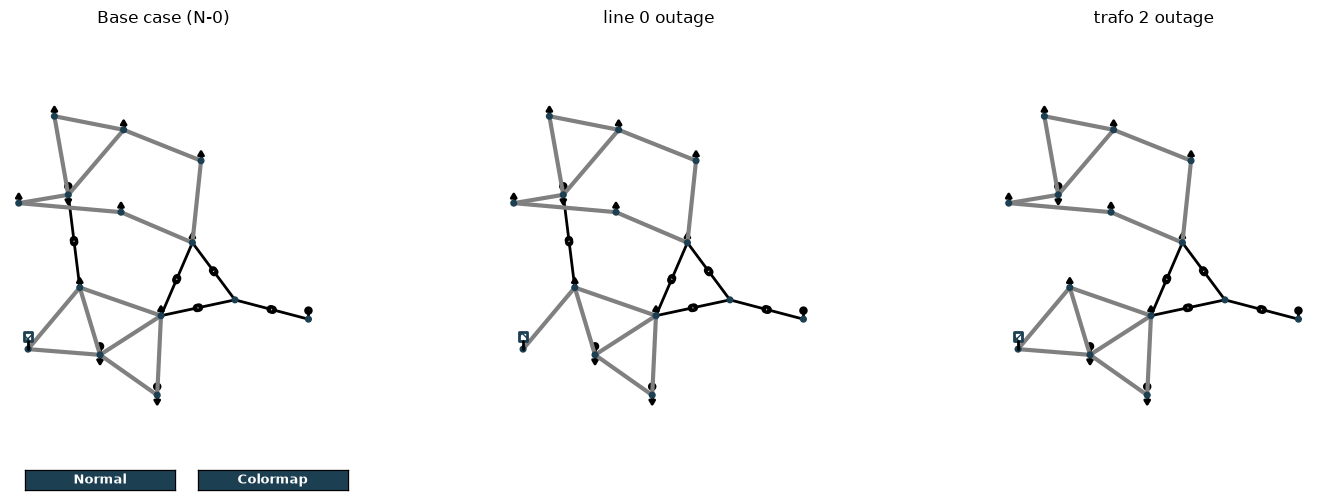

In [14]:
# generate network diagram
cases = [("None", None), ("line", 0), ("trafo", 2)]
fig, axes = plt.subplots(1, 3, figsize=(15,5)) # place images side-by-side

for ax, (elem, i) in zip(axes, cases):
    n = copy.deepcopy(net)
    if elem == "line":
        n.line.loc[i, "in_service"] = False
    elif elem == "trafo":
        n.trafo = n.trafo.drop(index=i) # remove transformer
    plot.simple_plot(n, plot_loads=True, plot_gens=True, show_plot=False, ax=ax)
    ax.set_title("Base case (N-0)" if elem == "None" else f"{elem} {i} outage")
    ax.autoscale()
    ax.axis("off")

plt.tight_layout()
fig.savefig("results/net_comparison.png", dpi=200, bbox_inches="tight")

**Base case**: In the base case, all elements are connected. The square symbol in the bottom-left corner identifies the slack bus, which connects to the rest of the network through two transmission lines. 

**Line 0 outage**: The gray line from the slack bus to bus 1 is missing, leaving the slack bus with a single link. All of its power flows through line 1, which overloads (111%) and trips next (see *cascade table* above).

**Transformer 2 outage**: The solid black link on the left, a transformer between bus 4 and 5, is missing. Its flow shifts to the remaining paths and overloads line 10 (117%), which tripes and overloads line 11.

### Corrective Actions

Devise a strategy to mitigate the effects of vulnerable line outages.

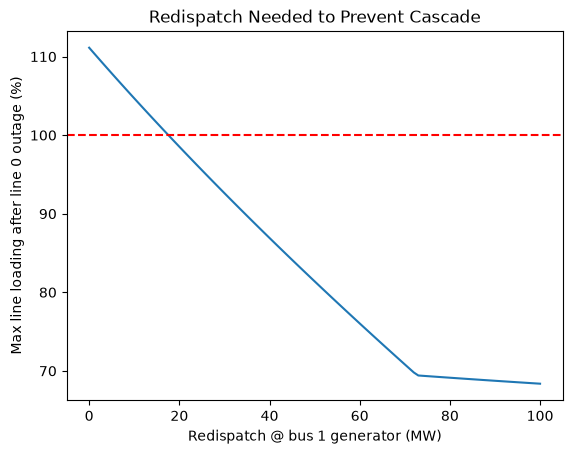

In [15]:
rows = []
for mw in range(101):
    corrected = redispatch(net, redispatch_mw=mw)
    status = sim_cascade(corrected, load_max, 0)["Cascade_Status"]
    rows.append({"Redispatch_MW": mw, 
                 "Status": status,
                 "Max_Loading": outage_result(corrected, 0)["Max_Line_Loading_%"],
                 })

sweep = pd.DataFrame(rows)

plt.plot(sweep["Redispatch_MW"], sweep["Max_Loading"])
plt.title("Redispatch Needed to Prevent Cascade")
plt.xlabel("Redispatch @ bus 1 generator (MW)")
plt.ylabel("Max line loading after line 0 outage (%)")
plt.axhline(100, linestyle="--", color="red") # mark loading limit
plt.show()

Line loading decreases as bus 1 generator increases output, dropping below 100% at around 18 MW. The curve plateaus near 74 MW as line 9 becomes most loaded.

In [16]:
# compare before and after 
first_stable = sweep.loc[sweep["Status"] == "Stable", "Redispatch_MW"].min()
comparison = pd.DataFrame([summary(0), summary(first_stable)], index=["Before", "After"]).T
display(comparison)
# print(comparison.to_markdown())

,Before,After
Redispatch_MW,0,18
N1_Status,Violation,Pass
Max _Line_Loading_%,111.1,99.7
Worst_Line,1,1
Cascade_Status,Blackout (islanded),Stable
Lines_Tripped,2,1
Load_Lost_MW,259.0,0.0


An 18 MW redispatch takes loading from 111.1% to 99.7%, restoring operation within the line's rated limit without load shedding in the N-1 case. However, the line operates very close to its maximum rated capacity. Although loading above 100% does not necessarily indicate immediate equipment failure, acceptable overloads depend on equipment ratings and operating conditions.

In [17]:
# load shedding: deliberate, temporary shutdown of electric supply to selected loads
shed_records = []

for load_id in net.load.index:
    n = copy.deepcopy(net)
    n.line.loc[0, "in_service"] = False # trip line 0 (N-1 case)
    n.load.loc[load_id, "in_service"] = False # shed a load
    try:
        pp.runpp(n)
        row = check_case(n) # reuse pass/violation check
    except pp.LoadflowNotConverged:
        row = {"Status": "Non-convergence", "Max_Line_Loading_%": np.nan}

    shed_only = copy.deepcopy(net)
    shed_only.load.loc[load_id, "in_service"] = False


    shed_records.append({
        "Shed_Bus": net.load.loc[load_id, "bus"],
        "Shed_Cost_MW": net.load.loc[load_id, "p_mw"],
        "Max_Line_Loading%": row["Max_Line_Loading_%"],
        "Fixes": row["Status"] == "Pass",
        "Cascade_Status": sim_cascade(shed_only, load_max, 0)["Cascade_Status"]
    })

# sort table based on fixes and shed cost
df_shed = (pd.DataFrame(shed_records)
           .sort_values(["Fixes", "Shed_Cost_MW"], ascending=[False, True])
           .reset_index(drop=True))
df_shed["Shed_%"] = 100 * df_shed["Shed_Cost_MW"] / net.load.p_mw.sum() # add shed % (~[shed cost/generated power]*100%)
display(df_shed.round(1).style.hide(axis="index"))


Shed_Bus,Shed_Cost_MW,Max_Line_Loading%,Fixes,Cascade_Status,Shed_%
1,21.700000,97.500000,True,Stable,8.400000
8,29.500000,92.800000,True,Stable,11.400000
3,47.800000,82.500000,True,Stable,18.500000
2,94.200000,67.400000,True,Stable,36.400000
10,3.500000,108.900000,False,Blackout (islanded),1.400000
11,6.100000,107.200000,False,Blackout (islanded),2.400000
4,7.600000,106.300000,False,Blackout (islanded),2.900000
9,9.000000,105.300000,False,Blackout (islanded),3.500000
5,11.200000,104.200000,False,Blackout (islanded),4.300000
12,13.500000,102.600000,False,Blackout (islanded),5.200000


Only individual loads were examined. Load shedding at buses 1, 8, 3, and 2 mitigated the cascade, with bus 1 requiring the least amount of load reduction (8.4% of total load). Redispatch is the preferred strategy because it prevents the cascade without interrupting demand. Load shedding remains a secondary measure.

### Rating Sensitivity

In [20]:
# Sweep sensitivity ratings and generate a summary table.
sweep_summary = []

for margin in [1.3, 1.5, 1.6, 1.66, 1.68, 1.7, 1.8, 2.0]:
    net_m = create_net(margin)
    n1_results = pd.concat([n1_case(net_m, "line"),
                     n1_case(net_m, "trafo"),
                     n1_case(net_m, "gen")], ignore_index=True)
    fail = n1_results[n1_results["Status"].isin(["Violation", "Non-convergence"])]
    cascades = pd.DataFrame([sim_cascade(net_m, load_max, i, k) for k, i in zip(fail["Element"], fail["Index"])])
    lost = cascades["Load_Lost_MW"] if len(cascades) else pd.Series(dtype=float)

    sweep_summary.append({
        "Margin": margin,
        "Violations": len(fail),
        "Elements": ", ".join(f"{k} {i}" for k, i in zip(fail["Element"], fail["Index"])),
        "Cascades_With_Load_Loss": int((lost > 0).sum()),
        "Worst_Load_Lost_MW": round(lost.max(), 1) if len(lost) else 0,
    })

summary_df = pd.DataFrame(sweep_summary)
display(summary_df)
# print(summary_df.to_markdown())

,Margin,Violations,Elements,Cascades_With_Load_Loss,Worst_Load_Lost_MW
0,1.30,6,"line 0, line 1, line 8, line 11, trafo 2, trafo 3",5,259.0
1,1.50,4,"line 0, line 1, trafo 2, trafo 3",3,259.0
2,1.60,3,"line 0, trafo 2, trafo 3",2,259.0
3,1.66,3,"line 0, trafo 2, trafo 3",2,259.0
4,1.68,2,"trafo 2, trafo 3",1,58.2
5,1.70,2,"trafo 2, trafo 3",1,58.2
6,1.80,1,trafo 3,0,0.0
7,2.00,1,trafo 3,0,0.0


At 1.3x and 1.5x ratings, six and four outages fail, respectively. At 1.8x and 2.0x, Transformer 3 is flagged for isolating bus 7, which has no load; therefore, no load is lost during the simulated cascades. These results show that critical line identification is sensitive to the assumed ratings.

### Limitations

- Analysis considers static power flow only
- Line ratings are my own assumption (test case provides placeholder values); all findings depend on these assumptions
- The 259 MW loss is an upper-bound estimate because the model assumes complete disconnection of the slack bus
- Corrective actions were studied for the line 0 outage only (single-load shedding and one generator)